**Stochastic Gradient Descent (SGD)** is the foundational optimization algorithm of machine learning and deep learning. Long before Adam or RMSprop existed, SGD laid the mathematical groundwork for how neural networks learn from data.

---

### Definition

**Stochastic Gradient Descent** is an iterative optimization method used to find the minimum of a loss function. Unlike traditional gradient descent, which calculates the error gradient using the **entire dataset** at once, SGD calculates the gradient using only **a single randomly selected sample** (or a small batch of samples) at each step.

The word *"stochastic"* means random—reflecting the fact that the algorithm takes random, noisy steps downhill based on individual data points.

---

### The Three Flavors of Gradient Descent

To truly understand SGD, it helps to see how it contrasts with the other two classic approaches:

1. **Batch Gradient Descent:**
* Uses the **entire dataset** to compute the gradient for a single step.
* *Pros:* Perfectly smooth path straight to the minimum.
* *Cons:* Computationally catastrophic and memory-intensive for large datasets. If you have 1 million images, processing all of them just to take *one* step is impossibly slow.


2. **Pure Stochastic Gradient Descent (SGD):**
* Uses **one random sample** at a time to compute the gradient and update weights.
* *Pros:* Extremely fast updates; can compute a step instantly even for massive datasets.
* *Cons:* Highly erratic and noisy. Instead of marching straight down a hill, the loss bounces wildly back and forth.


3. **Mini-Batch Gradient Descent (What we actually call "SGD" today):**
* Uses a **small batch** of samples (e.g., 32, 64, or 128 samples) per step.
* This is the sweet spot: it combines the computational efficiency of SGD with enough stability to make steady progress. **When deep learning libraries say `optim.SGD`, they mean Mini-Batch SGD.**



---

### The SGD Mathematical Update Rule

At every step $t$, the optimizer updates the model parameters (weights $w$ and biases $b$) using the gradient of the loss function calculated on a mini-batch:

$$w_{t+1} = w_t - \eta \nabla L(w_t)$$

* $w_t$: Current weights.
* $\eta$ (Eta): The **learning rate** (controls how big of a step to take).
* $\nabla L(w_t)$: The gradient of the loss function with respect to the weights.
* The minus sign (\-) ensures we move in the **opposite** direction of the gradient (i.e., downhill toward lower loss).

---

### Pros and Cons of Pure SGD

* **Advantages:**
* **Memory Efficient:** You don't need to load the entire dataset into RAM; you can stream data batch by batch.
* **Escapes Local Minima:** Because the updates are noisy, SGD can occasionally bounce out of shallow local traps or saddle points that would trap batch gradient descent.


* **Disadvantages:**
* **Noisy Convergence:** The loss curve fluctuates up and down rather than descending smoothly.
* **The "Ravine" Problem:** In high-dimensional spaces where the loss surface curves steeply in one direction and gently in another (like a steep canyon), pure SGD tends to oscillate uselessly back and forth across the walls instead of flowing down the valley.



---

### How Momentum Fixed SGD

To fix SGD's oscillation problem in ravines, researchers added **Momentum** (inspired by physics).

Instead of letting the current gradient dictate 100% of the next step, **SGD with Momentum** remembers the velocity of past steps. It builds up speed in consistent downward directions and dampens out side-to-side oscillations.

---

### PyTorch Implementation: SGD with Momentum

Here is how you instantiate and use standard SGD with momentum in PyTorch (using our vehicle telemetry model setup):

In [1]:
# Import necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
print("Libraries imported successfully!")

Libraries imported successfully!


### Step 1: Library Imports
In this initial cell, we load the required Python libraries:
* **`torch` & `torch.nn`**: Core PyTorch libraries for building neural network architectures and computational graphs.
* **`torch.optim`**: Contains optimization algorithms, including the **Stochastic Gradient Descent (SGD)** optimizer we are exploring.
* **`sklearn` Modules**: Used for generating high-quality synthetic data (`make_classification`), splitting data (`train_test_split`), and standardization (`StandardScaler`).
* **`matplotlib.pyplot`**: For plotting training history and performance curves.

In [2]:
# Generate synthetic vehicle telemetry dataset (4 features, 3 classes)
X_raw, y_raw = make_classification(
    n_samples=2000,
    n_features=4,
    n_informative=4,
    n_redundant=0,
    n_classes=3,
    random_state=42
)

# Split into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (1600, 4)
Testing set shape: (400, 4)


### Step 2: Dataset Creation & Splitting
To study SGD, we need a controlled sandbox environment. Here, we generate a synthetic dataset representing **vehicle telemetry features**:
* **Number of features**: 4 metrics (e.g., speed, engine temperature, vibration, battery level).
* **Classes**: 3 target classes representing different vehicle states (e.g., *Normal, Warning, Critical*).
* **Dataset Split**: We divide our 2,000 samples into **80% training data** (1,600 samples) to train the model and **20% testing data** (400 samples) to measure generalized accuracy.

In [3]:
# Standardize features (crucial for gradient-based optimizers like SGD)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert numpy arrays to PyTorch Tensors
X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

print("Data scaled and converted to PyTorch Tensors.")

Data scaled and converted to PyTorch Tensors.


### Step 3: Feature Scaling & PyTorch Tensor Conversion

#### Why Feature Scaling is Critical for SGD
Gradient descent-based optimizers are highly sensitive to the scale of input features. If one feature spans $[0, 1]$ and another spans $[0, 10000]$, the loss surface becomes heavily elongated like a narrow canyon. The optimizer will oscillate wildly back and forth across the steep walls rather than smoothly moving down the canyon floor.

```
   Unscaled Features (Elongated Valley)           Scaled Features (Symmetric Bowl)
             \           /                                     \       /
              \   _ _   /                                       \     /
               \/     \/                                         \___/
         (Oscillates wildly)                            (Smooth path to minimum)
```

* **`StandardScaler`**: Centers the dataset to have a mean of 0 and a standard deviation of 1.
* **Tensor Conversion**: Converts the NumPy arrays into PyTorch floating-point and long-integer tensors so they can reside in PyTorch's computational graph and process gradients.

In [4]:
class VehicleMLP(nn.Module):
    def __init__(self):
        super(VehicleMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(4, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 3) # Outputs raw logits for 3 classes
        )

    def forward(self, x):
        return self.network(x)

model = VehicleMLP()
print(model)

VehicleMLP(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Linear(in_features=16, out_features=3, bias=True)
  )
)


### Step 4: Model Architecture
We construct a **Multilayer Perceptron (MLP)** with PyTorch's `nn.Sequential` container:

```
  [Input: 4 Features] ---> [Linear: 32 Hidden Units] ---> [ReLU Activation] ---> [Dropout (p=0.2)]
                                                                                    |
  [Output Logits: 3]  <--- [Linear: 16 Hidden Units] <--- [ReLU Activation] <-------v
```

* **Activation (`ReLU`)**: Multi-layer networks require non-linear activations; otherwise, they simplify mathematically to a single linear layer.
* **Regularization (`Dropout`)**: Temporarily deactivates a random 20% of neurons during training to prevent the network from overfitting to the synthetic noise.

In [5]:
# Loss function
criterion = nn.CrossEntropyLoss()

# SGD Optimizer with Momentum and L2 Weight Decay
optimizer = optim.SGD(
    model.parameters(),
    lr=0.03,            # Initial learning rate
    momentum=0.9,       # Adds velocity from previous updates
    weight_decay=1e-4   # L2 regularization
)

# Step Learning Rate Scheduler (drops LR by 10x every 40 epochs)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=40, gamma=0.1)

print("Optimizer and Scheduler initialized.")

Optimizer and Scheduler initialized.


### Step 5: Optimizer & Learning Rate Scheduler

Here we configure our optimization parameters:
1. **Loss Function (`CrossEntropyLoss`)**: Evaluates how close the model's raw output logits match the true class targets.
2. **Momentum**: Accelerates updates in directions with consistent gradients and dampens oscillations, mimicking the physical momentum of a rolling ball.
3. **Weight Decay ($10^{-4}$)**: L2 regularization that slightly penalizes large model weights to prevent overfitting.
4. **StepLR Scheduler**: A learning rate scheduler that drops the learning rate dynamically by $10\times$ (multiplied by `gamma=0.1`) every 40 epochs, allowing coarse steps early on and fine-grained updates later.

In [6]:
epochs = 120
loss_history = []
lr_history = []

print("--- Starting Training with SGD + Momentum ---")
for epoch in range(epochs):
    model.train()

    # Forward pass
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)

    # Backward pass & optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Track metrics
    current_lr = scheduler.get_last_lr()[0]
    lr_history.append(current_lr)
    loss_history.append(loss.item())

    # Step the scheduler
    scheduler.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | Loss: {loss.item():.4f} | LR: {current_lr:.5f}")

print("Training complete!")

--- Starting Training with SGD + Momentum ---
Epoch [20/120] | Loss: 1.0241 | LR: 0.03000
Epoch [40/120] | Loss: 0.8334 | LR: 0.03000
Epoch [60/120] | Loss: 0.8037 | LR: 0.00300
Epoch [80/120] | Loss: 0.7941 | LR: 0.00300
Epoch [100/120] | Loss: 0.7935 | LR: 0.00030
Epoch [120/120] | Loss: 0.8019 | LR: 0.00030
Training complete!


### Step 6: The Training Loop
This cell executes the iterative training process. Over 120 epochs, the following loop occurs:
1. **Forward Pass**: The current model makes predictions `outputs` based on training features.
2. **Loss Calculation**: The loss function assesses performance against targets.
3. **Backward Pass**: PyTorch tracks gradients of the loss with respect to all parameters using `.backward()`.
4. **Weight Update**: `optimizer.step()` moves model weights in the direction opposite to the gradient.
5. **Scheduler Update**: Adjusts learning rate based on epoch landmarks.

In [7]:
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_t)
    _, predicted = torch.max(test_outputs, 1)
    accuracy = (predicted == y_test_t).sum().item() / y_test_t.size(0)
    print(f"\nFinal Test Accuracy: {accuracy * 100:.2f}%")


Final Test Accuracy: 67.00%


### Step 7: Model Evaluation
To measure true model performance, we evaluate it on the testing set (with gradients disabled via `torch.no_grad()` to conserve memory and runtime processing). The final classification accuracy reflects how well the trained network generalizes to unseen data.

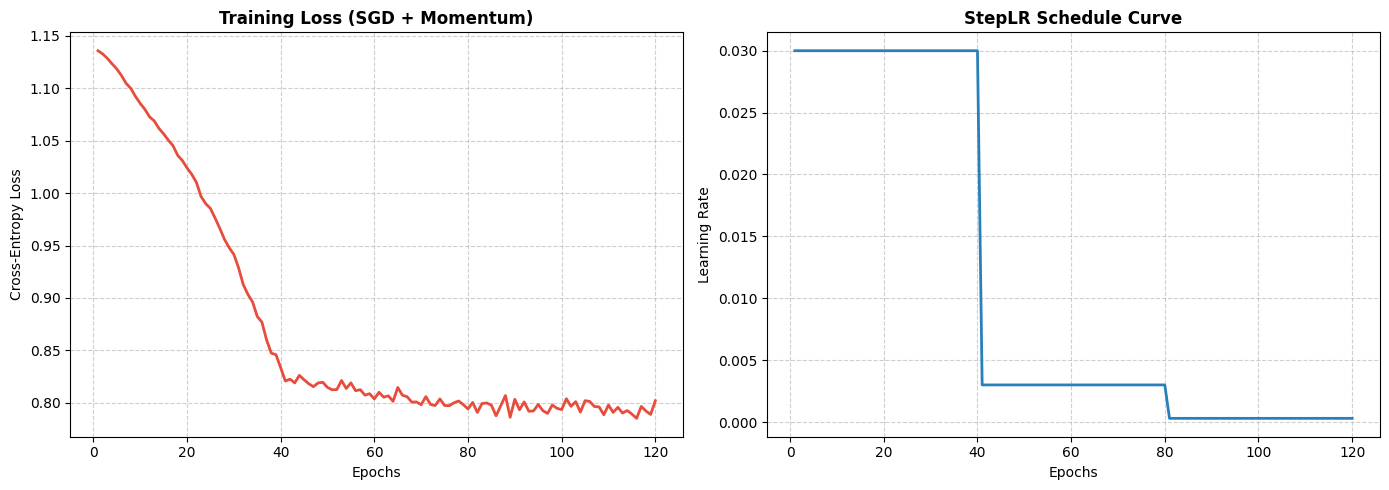

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Training Loss
axes[0].plot(range(1, epochs + 1), loss_history, color='#e74c3c', linewidth=2)
axes[0].set_title('Training Loss (SGD + Momentum)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epochs', fontsize=10)
axes[0].set_ylabel('Cross-Entropy Loss', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot Learning Rate Schedule (showing the step drop at epoch 40 and 80)
axes[1].plot(range(1, epochs + 1), lr_history, color='#2980b9', linewidth=2)
axes[1].set_title('StepLR Schedule Curve', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epochs', fontsize=10)
axes[1].set_ylabel('Learning Rate', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### Step 8: Visualizing Optimization Dynamics
These plots visualize the optimization journey:
* **Training Loss Curve**: Shows the drop in loss over time. Note how the loss curve starts noisy but stabilizes as training progresses and the learning rate is decayed.
* **Learning Rate Schedule Curve**: Visually displays the step changes in our learning rate at Epoch 40 and Epoch 80, showing how the schedule helps the model converge smoothly.